<a href="https://colab.research.google.com/github/chrisnelsonlab/BMEG4623/blob/master/6_Transport_FEM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src=https://brand.uark.edu/_resources/images/UA_Logo_Horizontal.jpg width="400" height="96">

####BMEG 4623 - Tranposrt phenomenon in biomedical engineering
####For more information, check out the Nelson lab for Therapeutic Genome Engineering (https://nelsonlab.uark.edu/)

For image credits, see the linked URL

#1. Introduction

The goal for today is to build an example FEM in heat transfer. The example is from teh MATLAB documentation here:
https://www.mathworks.com/help/pde/ug/heat-transfer-problem-with-temperature-dependent-properties.html


<img src=https://www.mathworks.com/help/examples/pde/heatedBlockWithSlot_01.png>

The model has a type I boundary condition on the left edge (labeled E4, watch out we are going to label it differently in python). We will set that equal to 100C

It also has a heat flux of -10 W/m^2 on the right edge (labled E2, again watch out we are changing that)

The remaining edges are all insulated


## 2. Let's install the toolkit (only needs to be run once)

In [1]:
!pip -q install scikit-fem meshpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.5/178.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 9.2 MB/s eta 0:00:00


## 3. Next, we will creat the object as a mesh of triangular elements. Let's expeiment with mesh size

Number of nodes: 638
Number of elements: 1167


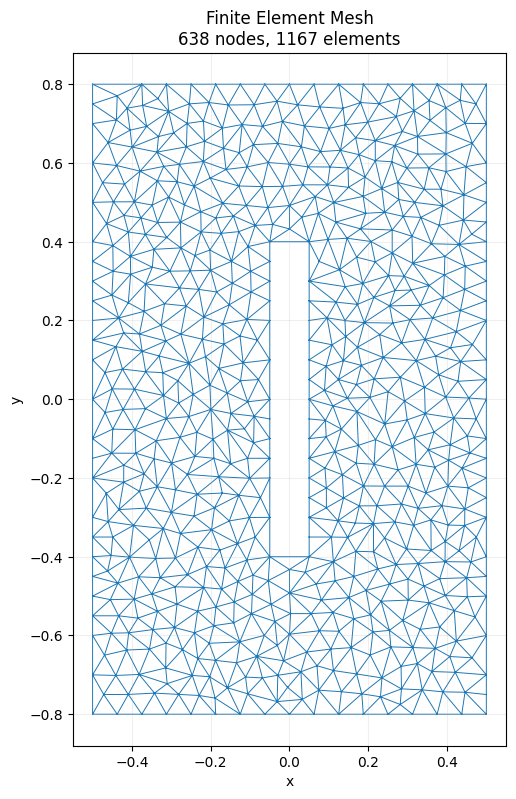

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from meshpy.triangle import MeshInfo, build
from skfem import MeshTri

#Define the geometry of the outer rectangle
outer = [
    (-0.5, -0.8),
    ( 0.5, -0.8),
    ( 0.5,  0.8),
    (-0.5,  0.8)
]

#Define the geometry of the "hole"
hole = [
    (-0.05, -0.4),
    ( 0.05, -0.4),
    ( 0.05,  0.4),
    (-0.05,  0.4)
]

#Merge the two lists
points = outer + hole

#This defines which "Points" are connected by "lines"
facets = [
    (0, 1), (1, 2), (2, 3), (3, 0),
    (4, 5), (5, 6), (6, 7), (7, 4)
]

def create_mesh(max_area):
    info = MeshInfo() #creates empty object
    info.set_points(points) #gives object our 8 points
    info.set_facets(
        facets, #Sends our facets from above
        facet_markers=[1, 1, 1, 1, 2, 2, 2, 2] #labels the markers for ease later 1-outside 2-hole
    )
    info.set_holes([(0.0, 0.0)]) #Don't include the "hole" in the mesh (contains the point 0,0). You can include multiple holes if needed

    generated = build(
        info,
        max_volume=max_area,  #We will use this parameter to get finer mesh
        min_angle=25
    )

    p = np.array(generated.points).T
    t = np.array(generated.elements).T

    return MeshTri(p, t)

mesh = create_mesh(0.002) #0.02 -> 120 elements #0.002 -> 1167 elements #0.0002 --> 11860

print("Number of nodes:", mesh.p.shape[1])
print("Number of elements:", mesh.t.shape[1])



#Visualize elements (Experiment with mesh size above)
fig, ax = plt.subplots(figsize=(8, 9))

#triplot - plots unstructured tiangular grids
ax.triplot(
    mesh.p[0],
    mesh.p[1],
    mesh.t.T,
    linewidth=0.7
)

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(
    f"Finite Element Mesh\n"
    f"{mesh.p.shape[1]} nodes, {mesh.t.shape[1]} elements"
)
ax.grid(True, alpha=0.2)

plt.show()

## 4. Now assign material properties and boundary conditions

Left boundary facets: 24
Left boundary nodes: 25
Right boundary facets: 25
Right boundary nodes: 26


/tmp/ipykernel_699/2366289530.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


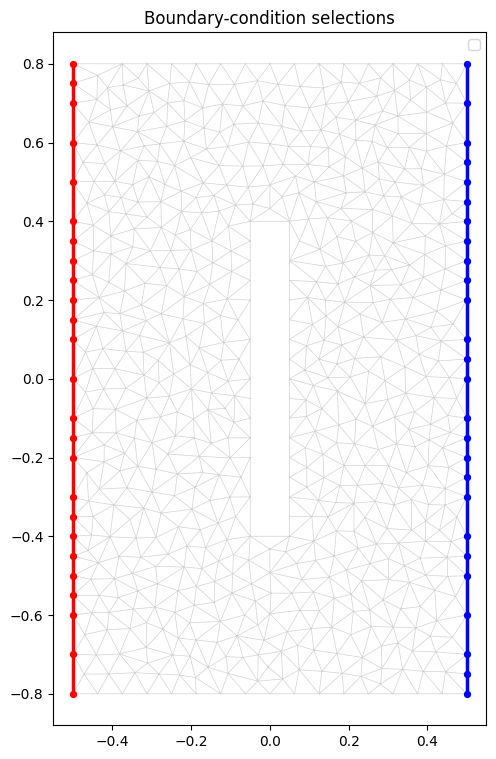

In [29]:
# Material property
k = 0.6


mesh = mesh.with_boundaries({
    "left": lambda x: np.isclose(x[0], -0.5, atol=tol),
    "right": lambda x: np.isclose(x[0],  0.5, atol=tol),
})

from skfem import Basis, ElementTriP1

basis = Basis(mesh, ElementTriP1())

left_facets = mesh.boundaries["left"]
right_facets = mesh.boundaries["right"]

left_dofs = basis.get_dofs("left").all()
right_dofs = basis.get_dofs("right").all()

print("Left boundary facets:", len(left_facets))
print("Left boundary nodes:", len(left_dofs))

print("Right boundary facets:", len(right_facets))
print("Right boundary nodes:", len(right_dofs))

fig, ax = plt.subplots(figsize=(7, 9))

ax.triplot(mesh.p[0], mesh.p[1], mesh.t.T,
           color="lightgray", linewidth=0.5)

# Highlight selected boundary facets
for facets, color, label in [
    (left_facets, "red", "Left: T = 100°C"),
    (right_facets, "blue", "Right: heat flux")
]:
    for f in facets:
        nodes = mesh.facets[:, f]
        xy = mesh.p[:, nodes]
        ax.plot(xy[0], xy[1], color=color, linewidth=2.5)

# Highlight selected degrees of freedom
ax.scatter(*mesh.p[:, left_dofs], color="red", s=18, zorder=3)
ax.scatter(*mesh.p[:, right_dofs], color="blue", s=18, zorder=3)

ax.set_aspect("equal")
ax.legend()
ax.set_title("Boundary-condition selections")
plt.show()

In [32]:
from skfem import FacetBasis

# Define the finite-element basis for the current mesh
basis = Basis(mesh, ElementTriP1())

# 1. Assemble the conductivity matrix
@BilinearForm
def conductivity(u, v, w):
    return k * dot(grad(u), grad(v))

K = asm(conductivity, basis)

# 2. Apply heat flux ONLY to the right outer face
q_in = -10.0

@LinearForm
def heat_flux(v, w):
    return q_in * v

right_facets = mesh.boundaries["right"]

flux_basis = FacetBasis(
    mesh,
    ElementTriP1(),
    facets=right_facets
)

F = asm(heat_flux, flux_basis)

# 3. Prescribe temperature ONLY on the left outer face
temperature_dofs = basis.get_dofs("left").all()
T_prescribed = 100.0

T = solve(
    *condense(
        K,
        F,
        x=np.full(basis.N, T_prescribed),
        D=temperature_dofs
    )
)

print(f"Minimum temperature: {T.min():.3f}")
print(f"Maximum temperature: {T.max():.3f}")

Minimum temperature: 73.945
Maximum temperature: 100.000


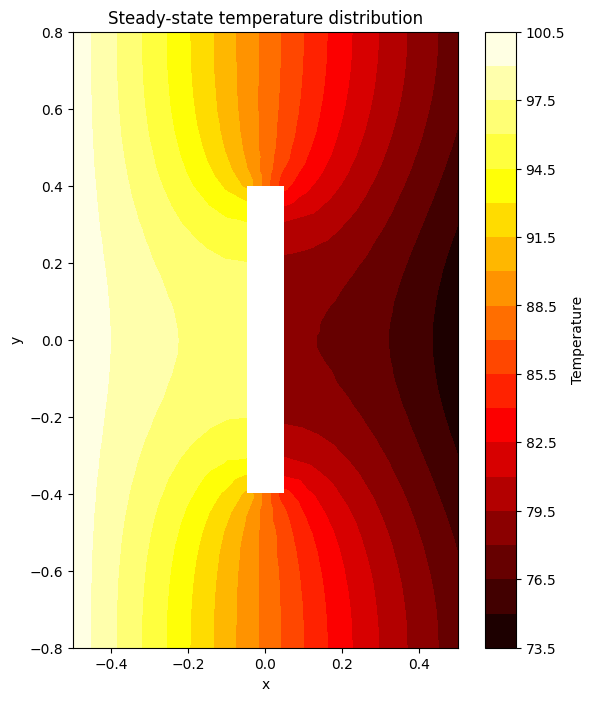

In [33]:
fig, ax = plt.subplots(figsize=(7, 8))

contours = ax.tricontourf(
    mesh.p[0],
    mesh.p[1],
    mesh.t.T,
    T,
    levels=25,
    cmap="hot"
)

fig.colorbar(contours, ax=ax, label="Temperature")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Steady-state temperature distribution")
plt.show()